In [1]:
import torch

if torch.cuda.is_available():
    print("GPU available:", torch.cuda.get_device_name(0))
else:
    print("GPU not available - using CPU")

GPU available: Tesla T4


In [2]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [3]:
!pip install -q diffusers transformers accelerate controlnet-aux safetensors

In [4]:
import torch
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel
from diffusers import UniPCMultistepScheduler

model_id = "runwayml/stable-diffusion-v1-5"
controlnet_id = "lllyasviel/sd-controlnet-canny"

controlnet = ControlNetModel.from_pretrained(
    controlnet_id,
    torch_dtype=torch.float16
)

pipe = StableDiffusionControlNetPipeline.from_pretrained(
    model_id,
    controlnet=controlnet,
    torch_dtype=torch.float16,
    safety_checker=None
)

pipe.scheduler = UniPCMultistepScheduler.from_config(
    pipe.scheduler.config
)

pipe = pipe.to("cuda")

print("ArchViz AI models loaded successfully!")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

... (2 outputs left out)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


ArchViz AI models loaded successfully!


In [6]:
from google.colab import files

uploaded = files.upload()

Saving Maison moderne en filaire architectural.png to Maison moderne en filaire architectural.png


Canny edge detection

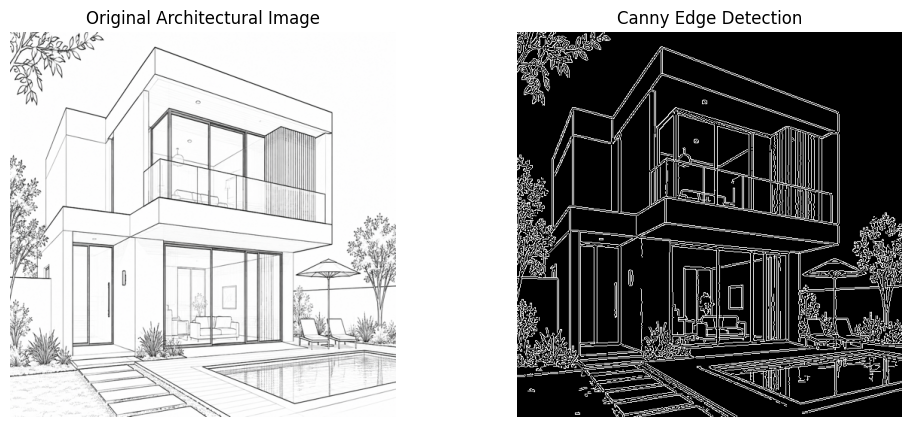

In [7]:
from PIL import Image
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load architectural image
image_path = "Maison moderne en filaire architectural.png"
image = Image.open(image_path).convert("RGB")

# Resize image
image = image.resize((512, 512))

# Convert to OpenCV format
image_np = np.array(image)

# Apply Canny edge detection
edges = cv2.Canny(image_np, 100, 200)

# Display original and edges
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Architectural Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.show()

Photorealistic

  0%|          | 0/25 [00:00<?, ?it/s]

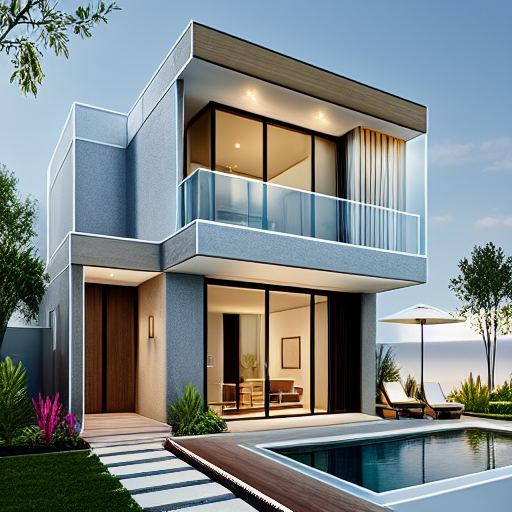

Image generated successfully!


In [11]:
from PIL import Image

# Prepare the control image
control_image = Image.fromarray(edges).convert("RGB")

# Generate realistic architectural rendering
prompt = """
Photorealistic architectural visualization of a luxury modern
two-story minimalist villa, white concrete facade, large glass
windows, elegant balcony, wooden vertical facade details,
beautiful swimming pool, landscaped garden, realistic materials,
natural daylight, professional architectural photography,
high detail, 4k rendering
"""

negative_prompt = """
distorted architecture, deformed building, extra floors,
warped windows, blurry, low quality, unrealistic proportions,
cartoon, sketch, drawing
"""

result = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    image=control_image,
    num_inference_steps=25,
    guidance_scale=8,
    controlnet_conditioning_scale=1.0,
    width=512,
    height=512
).images[0]

# Display result
display(result)

# Save result
result.save("ArchViz_AI_Result.png")

print("Image generated successfully!")

In [9]:
num_inference_steps=40,
guidance_scale=7,
controlnet_conditioning_scale=1.2,

  0%|          | 0/25 [00:00<?, ?it/s]

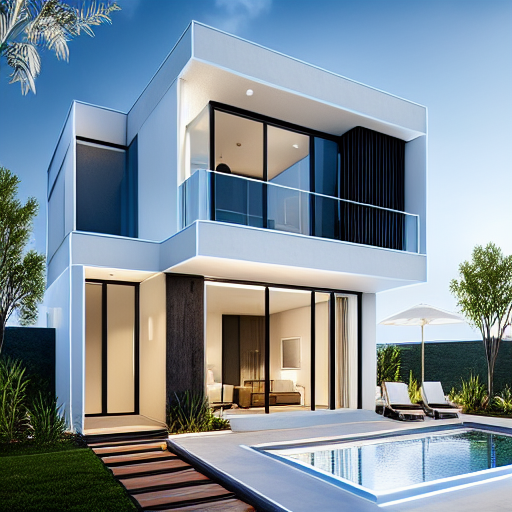

Image generated successfully!


In [10]:
from PIL import Image

# Prepare the control image
control_image = Image.fromarray(edges).convert("RGB")

# Generate realistic architectural rendering
prompt = """
Photorealistic architectural visualization of a luxury modern
two-story minimalist villa, white concrete facade, large glass
windows, elegant balcony, wooden vertical facade details,
beautiful swimming pool, landscaped garden, realistic materials,
natural daylight, professional architectural photography,
high detail, 4k rendering
"""

negative_prompt = """
distorted architecture, deformed building, extra floors,
warped windows, blurry, low quality, unrealistic proportions,
cartoon, sketch, drawing
"""

result = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    image=control_image,
    num_inference_steps=25,
    guidance_scale=8,
    controlnet_conditioning_scale=1.0,
    width=512,
    height=512
).images[0]

# Display result
display(result)

# Save result
result.save("ArchViz_AI_Result.png")

print("Image generated successfully!")
